<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Persiapan

In [46]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

RANDOM_STATE = 42

butuh = [f for f in ['Iris.csv'] if not os.path.exists(f)]
if butuh:
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print('File belum ditemukan:')
else:
    print('Semua dataset tersedia.')

Semua dataset tersedia.


---
# Praktikum 1 - K-Means pada Dataset Iris



### Langkah 1 - Persiapan data

In [47]:
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Langkah 2 - Seleksi fitur



In [48]:
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]
X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Langkah 3 - Plot data



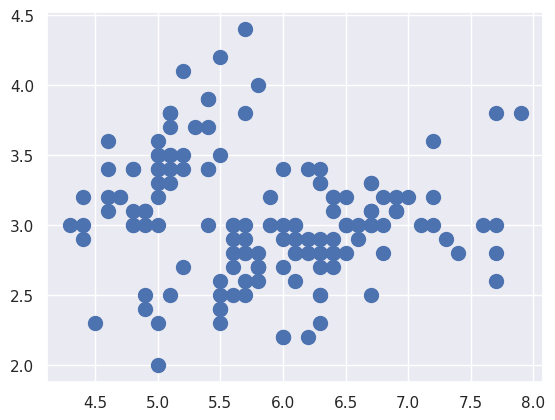

In [49]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.show()

### Langkah 4 - Model K-Means dengan k = 2



In [51]:
# Inisiasi objek KMeans
cl_kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

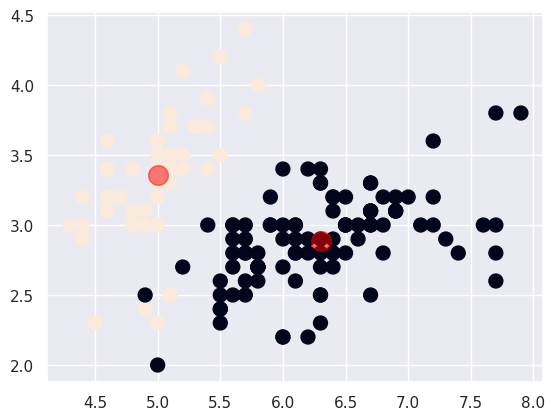

In [52]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.show()

### Langkah 5 - Nilai SSE

In [53]:
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


### Langkah 6 - Metode Elbow untuk mencari k terbaik

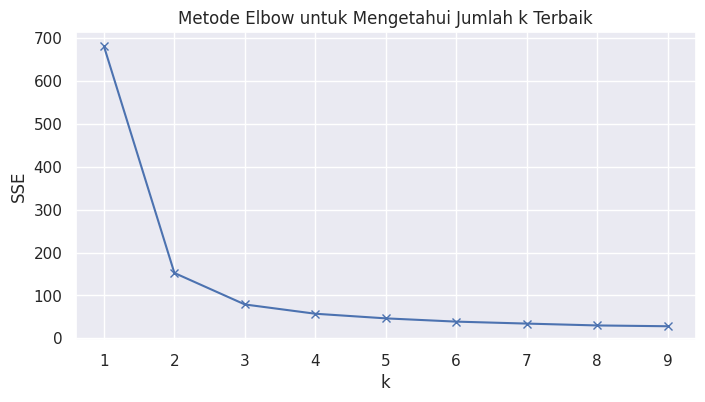

In [54]:
# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.show()

In [55]:
# Cek nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94084142614601
k=4; SSE=57.317873214285726
k=5; SSE=46.535582051282034
k=6; SSE=38.930963049671746
k=7; SSE=34.36020891600983
k=8; SSE=30.02341635819898
k=9; SSE=28.145502489617765
